# SUNSHIELD — Notebook 5: Plots & Final Files

Collects everything into the final plots and the 6 result files.

| Step | What happens | Output |
|---|---|---|
| 1 | Actual vs predicted plot for each split, red dots on anomalies | `actual_vs_predicted_*.png` |
| 2 | Plot showing the mean ± k·std band for every k | `sigma_bands.png` |
| 3 | Workflow diagram (training and testing, as in Dr. Mai's sketch) | `workflow.png` |
| 4 | File 1: Training Prediction (actual + predicted kW) | `1_LSTM_Training_Output_Prediction.csv` |
| 5 | File 2: Training Thresholding (actual 0/1 + predicted 0/1 for every k) | `2_LSTM_Training_Output_Thresholding.csv` |
| 6 | File 3: Validation Prediction | `3_LSTM_Validation_Output_Prediction.csv` |
| 7 | File 4: Validation Thresholding | `4_LSTM_Validation_Output_Thresholding.csv` |
| 8 | File 5: Testing Prediction | `5_LSTM_Testing_Output_Prediction.csv` |
| 9 | File 6: Testing Anomaly | `6_LSTM_Testing_Output_Anomaly.csv` |
| 10 | Check every plot: title, axis names with units, legend | check table |
| 11 | Zip and download all final files and plots | `final_outputs.zip` |

## Settings

In [1]:
import os, shutil, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

INVERTER = None       # None = the inverter with the most actual anomalies in the test split
SPLITS = ['train', 'val', 'test']
SPLIT_NAMES = {'train': 'Training', 'val': 'Validation', 'test': 'Testing'}
OUT_DIR = 'final_outputs'
os.makedirs(OUT_DIR, exist_ok=True)

# Chart style: actual = blue, predicted = orange, anomalies = red (same in every plot)
SURFACE, INK, INK_2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
BLUE, ORANGE, RED = '#2a78d6', '#eb6834', '#e34948'
BAND_BLUES = ['#184f95', '#2a78d6', '#6da7ec', '#9ec5f4', '#cde2fb']     # k = 1 (dark) … k = 3 (light)
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': GRID,
                     'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK_2,
                     'axes.titlecolor': INK, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2,
                     'legend.frameon': False, 'font.size': 10})
figures = {}          # every saved plot, checked in Step 10

## Upload Notebook 3 and Notebook 4 outputs

Run the cell below, click **Choose Files** and select **both** files together
(hold Ctrl, or Cmd on a Mac): `step3_outputs.zip` and `step4_outputs.zip`.

In [2]:
from google.colab import files
uploaded = files.upload()
for name in uploaded:
    shutil.unpack_archive(name, 'step3_outputs' if 'step3' in name else 'step4_outputs', 'zip')

anomalies = {s: pd.read_csv(f'step3_outputs/anomaly_{s}.csv', parse_dates=['DATE_TIME']) for s in SPLITS}
results = pd.read_csv('step4_outputs/results_best_k.csv', index_col='split')
best_k = float(results.loc['test', 'k'])

with open('step3_outputs/settings.txt') as f:
    nb3 = dict(line.strip().split(' = ', 1) for line in f if ' = ' in line)
MODE, PRUNING, MIN_HISTORY = nb3['MODE'], nb3['PRUNING'] == 'True', int(nb3['MIN_HISTORY'])
K_VALUES = [float(k) for k in nb3['K_VALUES'].strip('[]').split(',')]

if INVERTER is None:
    test = anomalies['test']
    INVERTER = test.groupby('SOURCE_KEY')[f'actual_anomaly_k{best_k:g}'].sum().idxmax()

print(f'Best k = {best_k:g} | MODE = {MODE} | PRUNING = {PRUNING} | plotted inverter = {INVERTER}')
results.round(3)

Best k = 2.5 | MODE = level | PRUNING = False | plotted inverter = LlT2YUhhzqhg5Sw


,k,TP,FP,FN,TN,precision,recall,F1
split,,,,,,,,
train,2.5,344,14,62,36071,0.961,0.847,0.901
val,2.5,195,69,48,11656,0.739,0.802,0.769
test,2.5,159,39,99,10461,0.803,0.616,0.697


## Step 1 — Actual vs predicted for each split, red dots on anomalies

One inverter (`INVERTER`) is shown for the whole split. Anomalies use the **best k**:
- **red dot** on the actual line = the actual line is an anomaly at that reading
- **red ring** on the predicted line = the predicted line is an anomaly at that reading

Night readings were removed in Notebook 1, so each night appears as a straight line between evening and morning.

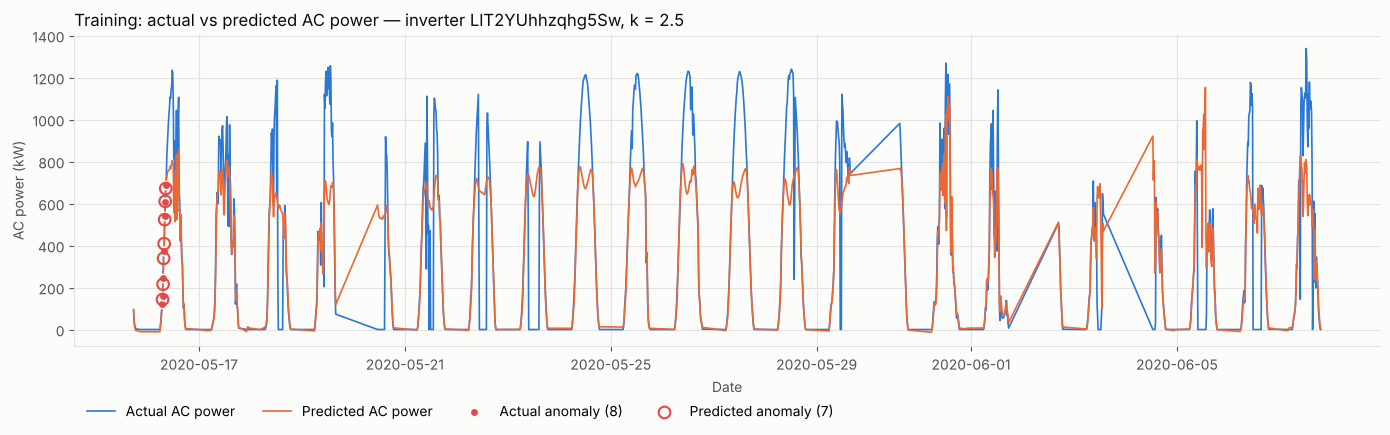

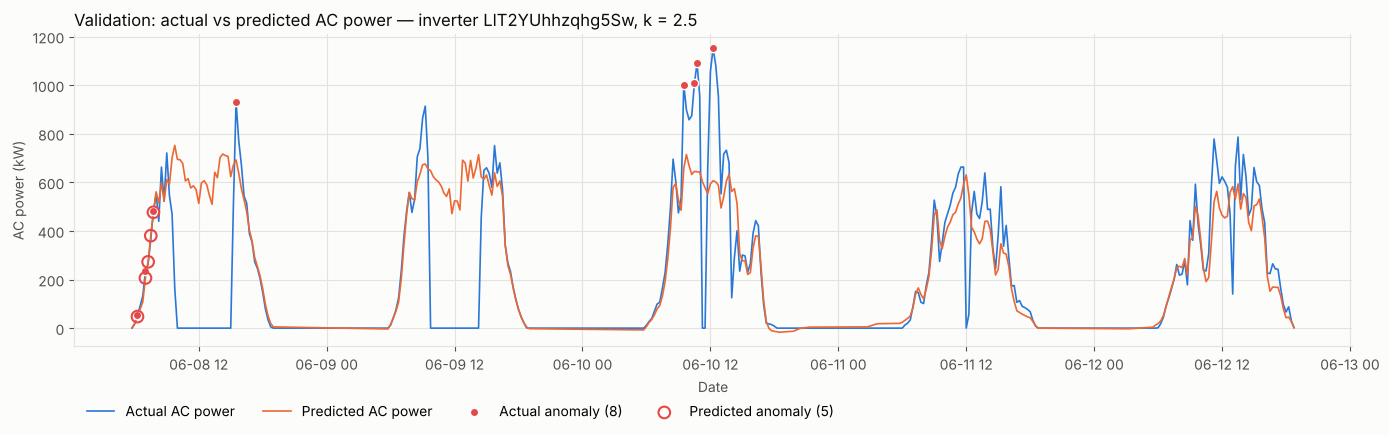

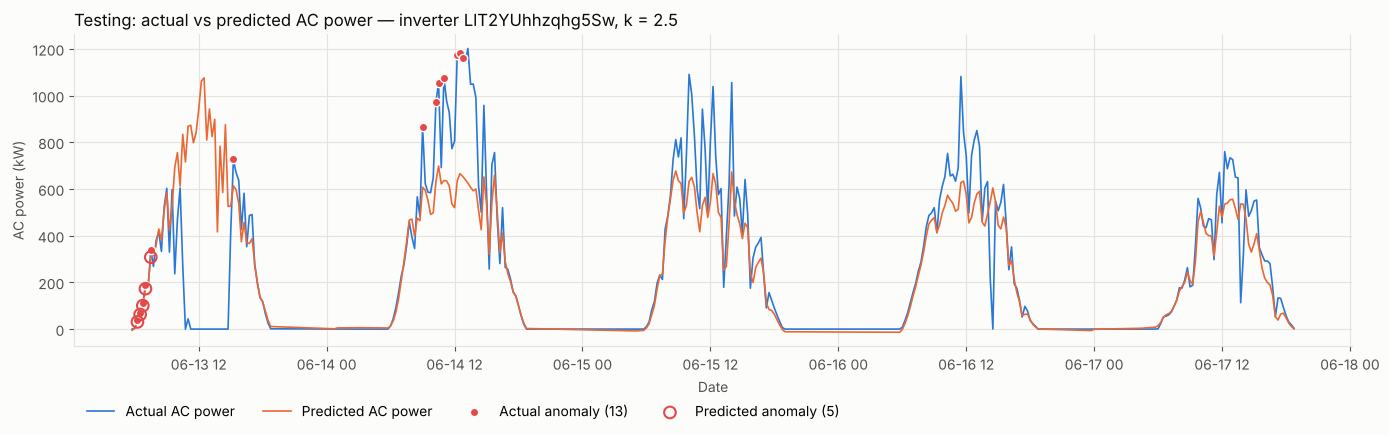

In [3]:
actual_col, predicted_col = f'actual_anomaly_k{best_k:g}', f'predicted_anomaly_k{best_k:g}'

for split in SPLITS:
    d = anomalies[split]
    d = d[d['SOURCE_KEY'] == INVERTER].sort_values('DATE_TIME')
    fig, ax = plt.subplots(figsize=(14, 4.5))
    ax.plot(d['DATE_TIME'], d['ACTUAL_AC_POWER_kW'], color=BLUE, linewidth=1.2, label='Actual AC power')
    ax.plot(d['DATE_TIME'], d['PREDICTED_AC_POWER_kW'], color=ORANGE, linewidth=1.2, label='Predicted AC power')
    a, p = d[d[actual_col] == 1], d[d[predicted_col] == 1]
    ax.scatter(a['DATE_TIME'], a['ACTUAL_AC_POWER_kW'], s=36, color=RED, zorder=3,
               edgecolors=SURFACE, linewidths=1, label=f'Actual anomaly ({len(a)})')
    ax.scatter(p['DATE_TIME'], p['PREDICTED_AC_POWER_kW'], s=70, facecolors='none', edgecolors=RED,
               linewidths=1.5, zorder=3, label=f'Predicted anomaly ({len(p)})')
    ax.set_title(f'{SPLIT_NAMES[split]}: actual vs predicted AC power — inverter {INVERTER}, k = {best_k:g}',
                 loc='left')
    ax.set_xlabel('Date')
    ax.set_ylabel('AC power (kW)')
    ax.legend(loc='upper left', ncol=4, bbox_to_anchor=(0, -0.14))
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, f'actual_vs_predicted_{split}.png'), dpi=150)
    figures[f'actual_vs_predicted_{split}.png'] = fig
    plt.show()

## Step 2 — The mean ± k·std band for every k

This is Dr. Mai's sketch on real data: the actual line of the test split, the mean of the previous readings,
and the bands mean ± k·std for k = 1 … 3. A reading outside the band of a k is an anomaly for that k;
the red dots are the anomalies for the best k.

`history_bands` repeats the Notebook 3 rule (previous readings only, same `MODE` and `PRUNING`), and the
check below confirms it gives exactly the same 0/1 as Notebook 3.

Same 0/1 as Notebook 3: True


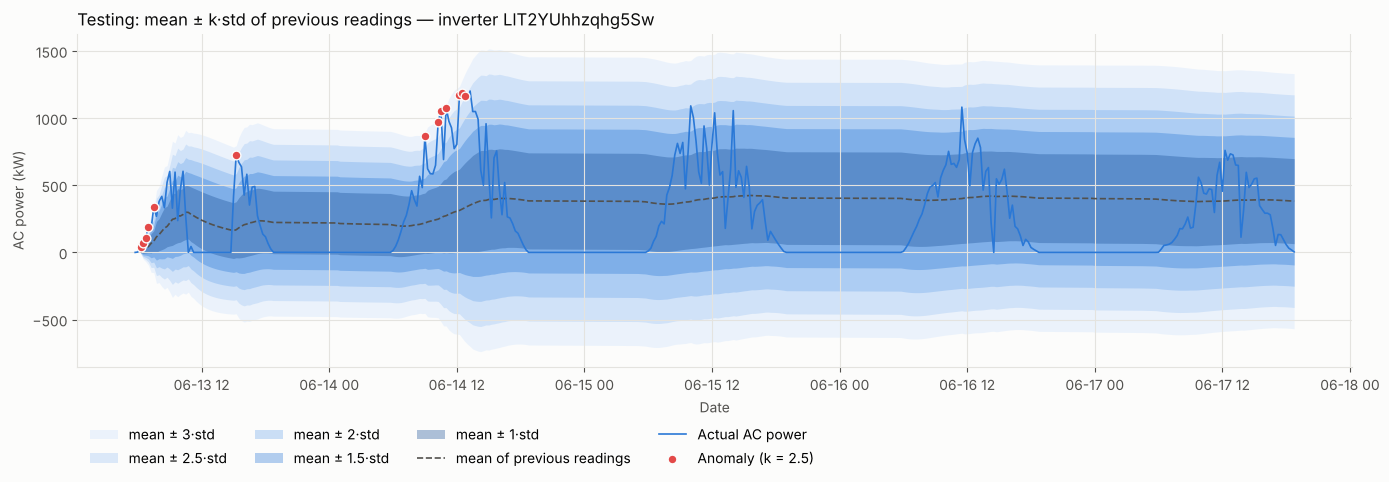

In [4]:
def history_bands(series, k):
    '''Mean and std of the PREVIOUS readings for every point (same rule and settings as Notebook 3).'''
    x = np.asarray(series, dtype=float)
    if MODE == 'change':
        x = np.diff(x, prepend=np.nan)
    mean_prev, std_prev = np.full(len(x), np.nan), np.full(len(x), np.nan)
    n, total, total_sq = 0, 0.0, 0.0
    for t, value in enumerate(x):
        if np.isnan(value):
            continue
        flagged = False
        if n >= MIN_HISTORY:
            mean_prev[t] = total / n
            std_prev[t] = np.sqrt(max((total_sq - n * mean_prev[t] ** 2) / (n - 1), 0.0))
            flagged = abs(value - mean_prev[t]) > k * std_prev[t]
        if not (PRUNING and flagged):
            n += 1
            total += value
            total_sq += value ** 2
    return x, mean_prev, std_prev

d = anomalies['test']
d = d[d['SOURCE_KEY'] == INVERTER].sort_values('DATE_TIME')
x, mean_best, std_best = history_bands(d['ACTUAL_AC_POWER_kW'], best_k)
same = ((np.abs(x - mean_best) > best_k * std_best).astype(int) == d[actual_col].to_numpy()).all()
print('Same 0/1 as Notebook 3:', same)

fig, ax = plt.subplots(figsize=(14, 5))
for k, color in sorted(zip(K_VALUES, BAND_BLUES), reverse=True):        # widest band first
    _, mean_k, std_k = history_bands(d['ACTUAL_AC_POWER_kW'], k)
    ax.fill_between(d['DATE_TIME'], mean_k - k * std_k, mean_k + k * std_k, color=color, alpha=0.35,
                    linewidth=0, label=f'mean ± {k:g}·std')
ax.plot(d['DATE_TIME'], mean_best, color=INK_2, linestyle='--', linewidth=1.2, label='mean of previous readings')
ax.plot(d['DATE_TIME'], x, color=BLUE, linewidth=1.2, label='Actual AC power' if MODE == 'level'
        else 'Change in actual AC power')
out = d[actual_col].to_numpy() == 1
ax.scatter(d['DATE_TIME'][out], x[out], s=40, color=RED, edgecolors=SURFACE, linewidths=1, zorder=3,
           label=f'Anomaly (k = {best_k:g})')
ax.set_title(f'Testing: mean ± k·std of previous readings — inverter {INVERTER}', loc='left')
ax.set_xlabel('Date')
ax.set_ylabel('AC power (kW)' if MODE == 'level' else 'Change in AC power (kW per 15 min)')
ax.legend(loc='upper left', ncol=4, bbox_to_anchor=(0, -0.14))
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'sigma_bands.png'), dpi=150)
figures['sigma_bands.png'] = fig
plt.show()

## Step 3 — Workflow diagram (training and testing, as in Dr. Mai's sketch)

Colors follow the plots: blue = actual line, orange = model / predicted line. The numbers come from
this run's results.

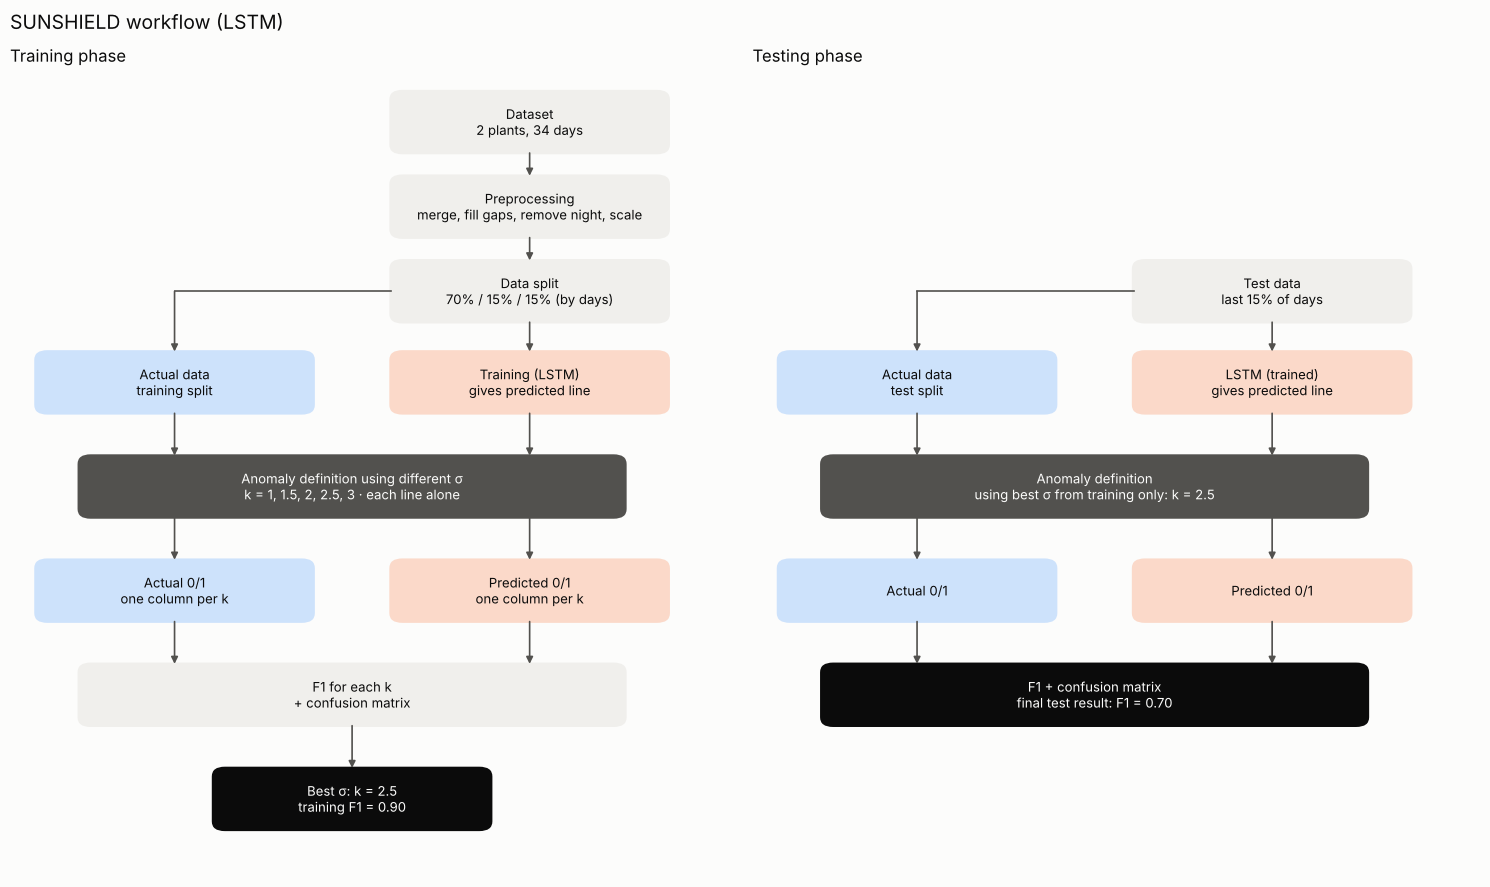

In [5]:
COLORS = {'step': ('#f0efec', INK), 'actual': ('#cde2fb', INK), 'model': ('#fbd9c9', INK),
          'rule': ('#52514e', SURFACE), 'result': ('#0b0b0b', SURFACE)}

def box(ax, x, y, text, kind='step', w=3.2, h=0.95):
    fill, ink = COLORS[kind]
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle='round,pad=0.02,rounding_size=0.15',
                                facecolor=fill, edgecolor='none'))
    ax.text(x, y, text, ha='center', va='center', color=ink, fontsize=9.5)
    return {'x': x, 'y': y, 'w': w, 'h': h}

def arrow(ax, start, end):
    ax.annotate('', xy=end, xytext=start,
                arrowprops=dict(arrowstyle='-|>', color=INK_2, lw=1.2, shrinkA=0, shrinkB=0))

def down(ax, a, b, x=None):            # vertical arrow from the bottom of box a to the top of box b
    x = a['x'] if x is None else x
    arrow(ax, (x, a['y'] - a['h'] / 2), (x, b['y'] + b['h'] / 2))

fig, (ax_train, ax_test) = plt.subplots(1, 2, figsize=(15, 9))
for ax in (ax_train, ax_test):
    ax.set_xlim(0, 8.4)
    ax.set_ylim(0, 12.4)
    ax.axis('off')

# Training phase
ax = ax_train
ax.set_title('Training phase', loc='left', fontsize=12)
dataset = box(ax, 6, 11.6, 'Dataset\n2 plants, 34 days')
prep = box(ax, 6, 10.3, 'Preprocessing\nmerge, fill gaps, remove night, scale')
split = box(ax, 6, 9.0, 'Data split\n70% / 15% / 15% (by days)')
lstm = box(ax, 6, 7.6, 'Training (LSTM)\ngives predicted line', 'model')
actual = box(ax, 1.9, 7.6, 'Actual data\ntraining split', 'actual')
rule = box(ax, 3.95, 6.0, f'Anomaly definition using different σ\nk = {", ".join(f"{k:g}" for k in K_VALUES)} · each line alone',
           'rule', w=6.3)
a01 = box(ax, 1.9, 4.4, 'Actual 0/1\none column per k', 'actual')
p01 = box(ax, 6, 4.4, 'Predicted 0/1\none column per k', 'model')
f1 = box(ax, 3.95, 2.8, 'F1 for each k\n+ confusion matrix', w=6.3)
best = box(ax, 3.95, 1.2, f'Best σ: k = {best_k:g}\ntraining F1 = {results.loc["train", "F1"]:.2f}', 'result')
down(ax, dataset, prep); down(ax, prep, split); down(ax, split, lstm)
ax.plot([split['x'] - split['w'] / 2, actual['x']], [split['y'], split['y']], color=INK_2, lw=1.2)
arrow(ax, (actual['x'], split['y']), (actual['x'], actual['y'] + actual['h'] / 2))
down(ax, actual, rule); down(ax, lstm, rule)
down(ax, rule, a01, x=a01['x']); down(ax, rule, p01, x=p01['x'])
down(ax, a01, f1); down(ax, p01, f1); down(ax, f1, best)

# Testing phase
ax = ax_test
ax.set_title('Testing phase', loc='left', fontsize=12)
test_data = box(ax, 6, 9.0, 'Test data\nlast 15% of days')
lstm = box(ax, 6, 7.6, 'LSTM (trained)\ngives predicted line', 'model')
actual = box(ax, 1.9, 7.6, 'Actual data\ntest split', 'actual')
rule = box(ax, 3.95, 6.0, f'Anomaly definition\nusing best σ from training only: k = {best_k:g}', 'rule', w=6.3)
a01 = box(ax, 1.9, 4.4, 'Actual 0/1', 'actual')
p01 = box(ax, 6, 4.4, 'Predicted 0/1', 'model')
final = box(ax, 3.95, 2.8, f'F1 + confusion matrix\nfinal test result: F1 = {results.loc["test", "F1"]:.2f}',
            'result', w=6.3)
down(ax, test_data, lstm)
ax.plot([test_data['x'] - test_data['w'] / 2, actual['x']], [test_data['y'], test_data['y']], color=INK_2, lw=1.2)
arrow(ax, (actual['x'], test_data['y']), (actual['x'], actual['y'] + actual['h'] / 2))
down(ax, actual, rule); down(ax, lstm, rule)
down(ax, rule, a01, x=a01['x']); down(ax, rule, p01, x=p01['x'])
down(ax, a01, final); down(ax, p01, final)

fig.suptitle('SUNSHIELD workflow (LSTM)', x=0.01, ha='left', fontsize=14, color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'workflow.png'), dpi=150)
figures['workflow.png'] = fig
plt.show()

## Steps 4–9 — The 6 result files

| File | Split | Columns |
|---|---|---|
| 1 Training Prediction | train | inverter, time, actual kW, predicted kW |
| 2 Training Thresholding | train | inverter, time, actual 0/1 and predicted 0/1 for **every k** (k is chosen here) |
| 3 Validation Prediction | val | inverter, time, actual kW, predicted kW |
| 4 Validation Thresholding | val | inverter, time, actual 0/1, predicted 0/1 with the **best k**, result (TP/FP/FN/TN) |
| 5 Testing Prediction | test | inverter, time, actual kW, predicted kW |
| 6 Testing Anomaly | test | inverter, time, actual and predicted kW, actual 0/1, predicted 0/1 with the **best k**, result |

In [6]:
ID = ['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME']
KW = ['ACTUAL_AC_POWER_kW', 'PREDICTED_AC_POWER_kW']
ALL_K = [f'{line}_anomaly_k{k:g}' for line in ('actual', 'predicted') for k in K_VALUES]

def with_best_k(df, keep_kw=False):
    out = df[ID + (KW if keep_kw else [])].copy()
    out['K'] = best_k
    out['ACTUAL_ANOMALY'] = df[actual_col]
    out['PREDICTED_ANOMALY'] = df[predicted_col]
    out['RESULT'] = np.select(
        [(out.ACTUAL_ANOMALY == 1) & (out.PREDICTED_ANOMALY == 1), (out.ACTUAL_ANOMALY == 0) & (out.PREDICTED_ANOMALY == 1),
         (out.ACTUAL_ANOMALY == 1) & (out.PREDICTED_ANOMALY == 0)], ['TP', 'FP', 'FN'], default='TN')
    return out

final_files = {
    '1_LSTM_Training_Output_Prediction.csv':     anomalies['train'][ID + KW],
    '2_LSTM_Training_Output_Thresholding.csv':   anomalies['train'][ID + ALL_K],
    '3_LSTM_Validation_Output_Prediction.csv':   anomalies['val'][ID + KW],
    '4_LSTM_Validation_Output_Thresholding.csv': with_best_k(anomalies['val']),
    '5_LSTM_Testing_Output_Prediction.csv':      anomalies['test'][ID + KW],
    '6_LSTM_Testing_Output_Anomaly.csv':         with_best_k(anomalies['test'], keep_kw=True),
}
for name, df in final_files.items():
    df.to_csv(os.path.join(OUT_DIR, name), index=False)
    print(f'{name:45s} {len(df):7,} rows  {df.shape[1]:2d} columns')

# The RESULT column must give the same counts as Notebook 4
test_counts = final_files['6_LSTM_Testing_Output_Anomaly.csv']['RESULT'].value_counts()
assert all(test_counts.get(c, 0) == results.loc['test', c] for c in ['TP', 'FP', 'FN', 'TN'])
print('\nTesting counts match Notebook 4:', test_counts.to_dict())
final_files['6_LSTM_Testing_Output_Anomaly.csv'].head()

1_LSTM_Training_Output_Prediction.csv          36,491 rows   5 columns
2_LSTM_Training_Output_Thresholding.csv        36,491 rows  13 columns
3_LSTM_Validation_Output_Prediction.csv        11,968 rows   5 columns
4_LSTM_Validation_Output_Thresholding.csv      11,968 rows   7 columns


5_LSTM_Testing_Output_Prediction.csv           10,758 rows   5 columns
6_LSTM_Testing_Output_Anomaly.csv              10,758 rows   9 columns

Testing counts match Notebook 4: {'TN': 10461, 'TP': 159, 'FN': 99, 'FP': 39}


,PLANT_ID,SOURCE_KEY,DATE_TIME,ACTUAL_AC_POWER_kW,PREDICTED_AC_POWER_kW,K,ACTUAL_ANOMALY,PREDICTED_ANOMALY,RESULT
0,4135001,1BY6WEcLGh8j5v7,2020-06-13 05:45:00,0.000000,-3.514679,2.5,0,0,TN
1,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:00:00,9.162500,13.575562,2.5,0,0,TN
2,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:15:00,33.228571,38.895020,2.5,1,1,TP
3,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:30:00,55.037500,61.439117,2.5,0,0,TN
4,4135001,1BY6WEcLGh8j5v7,2020-06-13 06:45:00,102.142857,96.193695,2.5,1,0,FN


## Step 10 — Check every plot: title, axis names with units, legend

The workflow diagram is a drawing, not a chart, so it only needs a title.

In [7]:
UNITS = ['(kW', 'Date']
rows = []
for name, fig in figures.items():
    ax = fig.axes[0]
    is_chart = name != 'workflow.png'
    title = ax.get_title(loc='left') or ax.get_title() or (fig._suptitle.get_text() if fig._suptitle else '')
    rows.append({'plot': name,
                 'title': bool(title),
                 'x axis name': ax.get_xlabel() if is_chart else '—',
                 'y axis name': ax.get_ylabel() if is_chart else '—',
                 'units in y axis': any(u in ax.get_ylabel() for u in UNITS) if is_chart else '—',
                 'legend': ax.get_legend() is not None if is_chart else '—'})
check = pd.DataFrame(rows).set_index('plot')
assert check['title'].all()
assert all(v in (True, '—') for v in check['units in y axis']) and all(v in (True, '—') for v in check['legend'])
print('All plots have a title, named axes with units, and a legend.')
check

All plots have a title, named axes with units, and a legend.


,title,x axis name,y axis name,units in y axis,legend
plot,,,,,
actual_vs_predicted_train.png,True,Date,AC power (kW),True,True
actual_vs_predicted_val.png,True,Date,AC power (kW),True,True
actual_vs_predicted_test.png,True,Date,AC power (kW),True,True
sigma_bands.png,True,Date,AC power (kW),True,True
workflow.png,True,—,—,—,—


## Step 11 — Zip and download all final files and plots

`final_outputs.zip` holds the 6 files, the plots of this notebook, and the Notebook 4 results
(metrics, best k, confusion matrices, precision/recall/F1 vs k) so everything for the report is in one place.

In [8]:
for f in glob.glob('step4_outputs/*'):
    shutil.copy(f, OUT_DIR)

shutil.make_archive('final_outputs', 'zip', OUT_DIR)
for f in sorted(os.listdir(OUT_DIR)):
    print(f'{f:45s} {os.path.getsize(os.path.join(OUT_DIR, f)) / 1e6:6.2f} MB')

files.download('final_outputs.zip')

1_LSTM_Training_Output_Prediction.csv           2.39 MB
2_LSTM_Training_Output_Thresholding.csv         2.34 MB
3_LSTM_Validation_Output_Prediction.csv         0.78 MB
4_LSTM_Validation_Output_Thresholding.csv       0.66 MB
5_LSTM_Testing_Output_Prediction.csv            0.71 MB
6_LSTM_Testing_Output_Anomaly.csv               0.83 MB
actual_vs_predicted_test.png                    0.20 MB
actual_vs_predicted_train.png                   0.25 MB
actual_vs_predicted_val.png                     0.19 MB
best_k.txt                                      0.00 MB
confusion_matrices_train.png                    0.11 MB
confusion_matrix_test.png                       0.03 MB
confusion_matrix_val.png                        0.03 MB
metrics_all_k.csv                               0.00 MB
metrics_vs_k.png                                0.09 MB
results_best_k.csv                              0.00 MB
sigma_bands.png                                 0.19 MB
workflow.png                                    